In [76]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import LogisticRegression

In [77]:
df=pd.read_csv("../data/train.csv")
df.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [78]:
df=df.drop(['Unnamed: 0', 'id'], axis=1)
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103899,Female,disloyal Customer,23,Business travel,Eco,192,2,1,2,3,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,Male,Loyal Customer,49,Business travel,Business,2347,4,4,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,Male,disloyal Customer,30,Business travel,Business,1995,1,1,1,3,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,1,5,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied


In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding                    1039

In [80]:
def encode_satisfaction(x):
    if x == 'satisfied':
        return 1
    elif x == 'neutral or dissatisfied':
        return 0

In [81]:
transformed_df=pd.get_dummies(df[df.columns[:-1]])
transformed_df['satisfaction']=df['satisfaction'].apply(encode_satisfaction)
transformed_df

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus,satisfaction
0,13,460,3,4,3,1,5,3,5,5,...,0,1,1,0,0,1,0,0,1,0
1,25,235,3,2,3,3,1,3,1,1,...,0,1,0,1,1,0,1,0,0,0
2,26,1142,2,2,2,2,5,5,5,5,...,1,0,1,0,1,0,1,0,0,1
3,25,562,2,5,5,5,2,2,2,2,...,1,0,1,0,1,0,1,0,0,0
4,61,214,3,3,3,3,4,5,5,3,...,0,1,1,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103899,23,192,2,1,2,3,2,2,2,2,...,1,0,0,1,1,0,0,1,0,0
103900,49,2347,4,4,4,4,2,4,5,5,...,0,1,1,0,1,0,1,0,0,1
103901,30,1995,1,1,1,3,4,1,5,4,...,0,1,0,1,1,0,1,0,0,0
103902,22,1000,1,1,1,5,1,1,1,1,...,1,0,0,1,1,0,0,1,0,0


In [82]:
transformed_df.loc[transformed_df['Arrival Delay in Minutes'].isnull()]

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus,satisfaction
213,38,109,5,3,3,3,5,5,5,5,...,1,0,1,0,1,0,0,1,0,1
1124,53,1012,3,2,3,4,4,3,4,4,...,0,1,1,0,0,1,0,1,0,0
1529,39,733,2,5,5,5,2,4,3,2,...,0,1,1,0,1,0,1,0,0,0
2004,26,1035,3,3,3,1,2,3,2,2,...,1,0,0,1,1,0,1,0,0,0
2108,24,417,2,1,2,2,5,2,5,5,...,1,0,1,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102067,49,1249,2,5,2,3,2,3,3,3,...,0,1,1,0,0,1,0,0,1,0
102384,58,733,3,3,3,3,3,3,3,3,...,0,1,1,0,1,0,0,1,0,0
102552,29,1107,2,1,1,1,5,1,3,5,...,1,0,0,1,1,0,0,1,0,0
102960,58,1088,4,4,1,1,5,4,5,5,...,0,1,1,0,1,0,0,1,0,1


In [83]:
imputer = KNNImputer(n_neighbors=5, weights="uniform")
transformed_df = pd.DataFrame(imputer.fit_transform(transformed_df),columns = transformed_df.columns)
transformed_df.to_csv("imputedAirlineDataset.csv",index=False)

In [84]:
transformed_df.loc[transformed_df['Arrival Delay in Minutes'].isnull()]

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus,satisfaction


<AxesSubplot: >

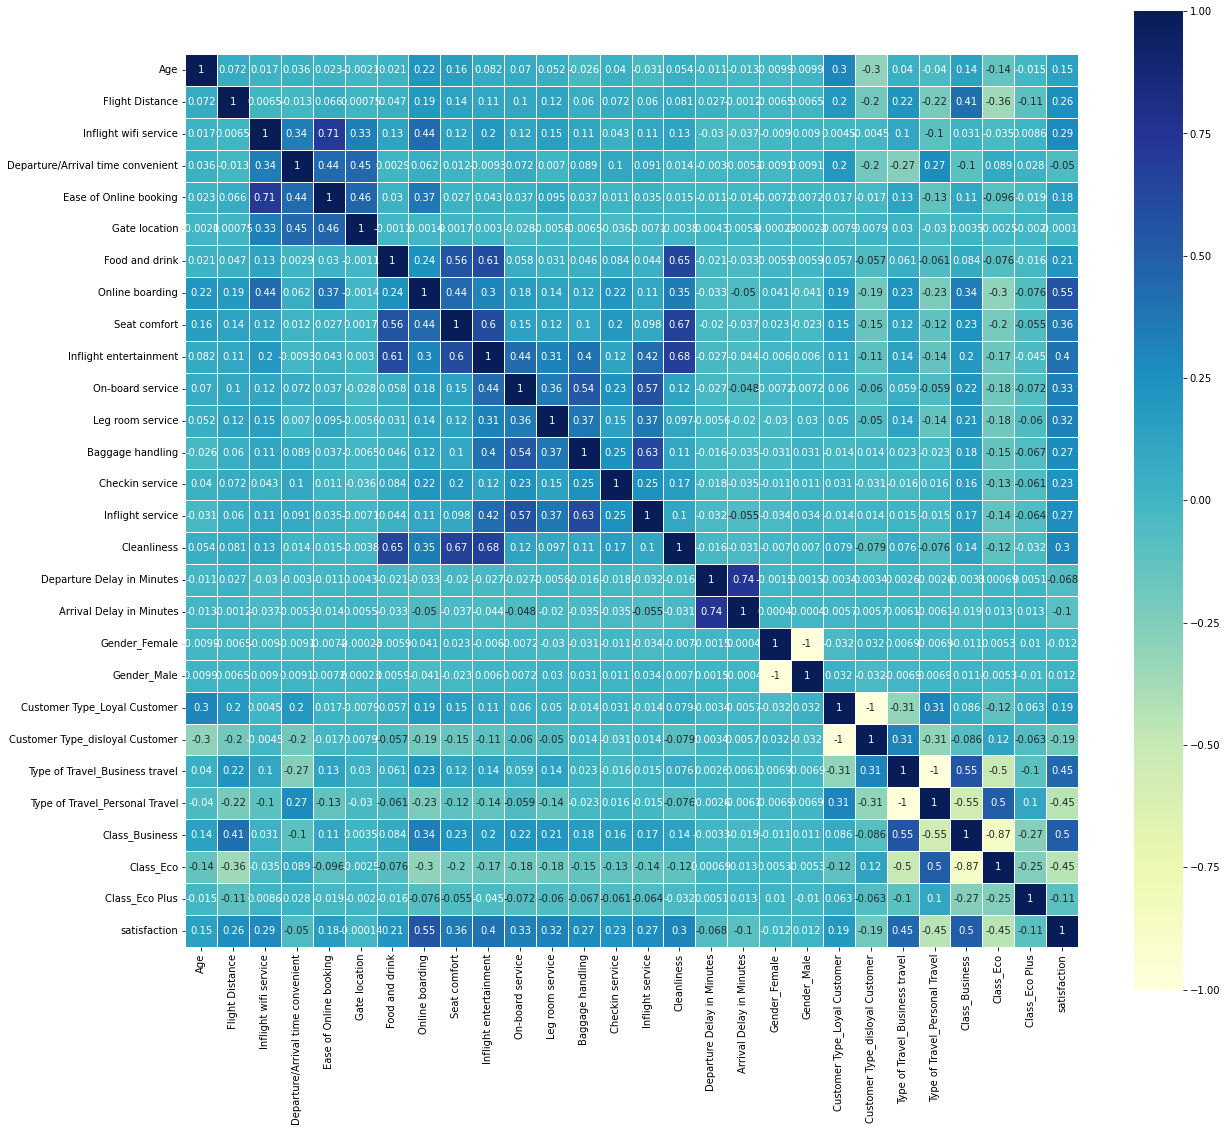

In [85]:
corr = transformed_df.corr(method='spearman')

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(20, 18))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, annot = True, cmap="YlGnBu", center=0,
            square=True, linewidths=.5)

In [86]:
X_train=transformed_df[transformed_df.columns[:-1]].to_numpy()
y_train=transformed_df[transformed_df.columns[-1]].to_numpy()
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

In [87]:
X_train.shape

(103904, 27)

In [88]:
test_df=pd.read_csv("../data/test.csv")
test_df=test_df.drop(['Unnamed: 0', 'id'], axis=1)
transformed_df=pd.get_dummies(test_df[test_df.columns[:-1]])
transformed_df['satisfaction']=test_df['satisfaction'].apply(encode_satisfaction)
imputer = KNNImputer(n_neighbors=5, weights="uniform")
transformed_df = pd.DataFrame(imputer.fit_transform(transformed_df),columns = transformed_df.columns)
X_test=transformed_df[transformed_df.columns[:-1]].to_numpy()
y_test=transformed_df[transformed_df.columns[-1]].to_numpy()
scaler = StandardScaler()
X_test = scaler.fit_transform(X_test)

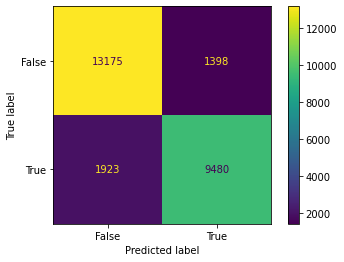

In [92]:
#Logistic Regression Model and Confusion Matrix

clf2 = LogisticRegression(random_state=0).fit(X_train, y_train)
y_pred2=clf2.predict(X_test)
from sklearn import metrics

confusion_matrix = metrics.confusion_matrix(y_test, y_pred2)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True])

cm_display.plot()
plt.show()

In [93]:
#Logistic Regression Model Metrics
Accuracy = metrics.accuracy_score(y_test, y_pred2)
Precision = metrics.precision_score(y_test, y_pred2)
Sensitivity_recall = metrics.recall_score(y_test, y_pred2)
Specificity = metrics.recall_score(y_test, y_pred2, pos_label=0)
F1_score = metrics.f1_score(y_test, y_pred2)
#metrics
print({"Accuracy":Accuracy,"Precision":Precision,"Sensitivity_recall":Sensitivity_recall,"Specificity":Specificity,"F1_score":F1_score})

{'Accuracy': 0.8721512165075455, 'Precision': 0.8714837286265857, 'Sensitivity_recall': 0.831360168376743, 'Specificity': 0.9040691690111851, 'F1_score': 0.8509492392621517}


In [94]:
#Random Forest Classifier Model and Confusion Matrix

rf_grid = {'n_estimators': [int(x) for x in np.linspace(200, 1000, 5)],
               'max_features': ['sqrt','log2']}

rf_model=RandomForestClassifier()
rnd_search = RandomizedSearchCV(RandomForestClassifier(),rf_grid,cv=5,verbose=5)
rnd_search.fit(X_train,y_train)
print(rnd_search.best_params_)
rnd_search.best_score_

In [95]:
rf_model=RandomForestClassifier(n_estimators=300,max_features="sqrt")
rf_model.fit(X_train,y_train)
#y_test=rf_model.predict(X_test)

RandomForestClassifier(max_features='sqrt', n_estimators=300)

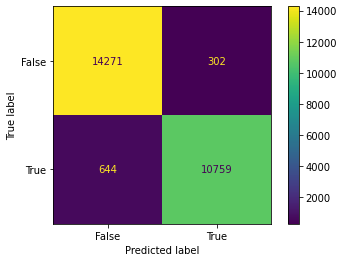

In [96]:
y_pred=rf_model.predict(X_test)
confusion_matrix2 = metrics.confusion_matrix(y_test, y_pred)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix2, display_labels = [False, True])

cm_display.plot()
plt.show()

In [97]:
#Random Forest Classifier Metrics
Accuracy2 = metrics.accuracy_score(y_test, y_pred)
Precision = metrics.precision_score(y_test, y_pred)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
F1_score = metrics.f1_score(y_test, y_pred)
#metrics
print({"Accuracy":Accuracy2,"Precision":Precision,"Sensitivity_recall":Sensitivity_recall,"Specificity":Specificity,"F1_score":F1_score})

{'Accuracy': 0.9635817677856483, 'Precision': 0.9726968628514601, 'Sensitivity_recall': 0.943523634131369, 'Specificity': 0.9792767446647911, 'F1_score': 0.9578881766381766}


In [98]:
#Adaboost Classifier Model and Confusion Matrix

adaboostGrid={"n_estimators":[int(x) for x in np.linspace(20,80,4)],"learning_rate":[int(x) for x in np.linspace(1,3,1)]}

In [99]:
ad_model=AdaBoostClassifier(random_state=0)
rnd_search = RandomizedSearchCV(ad_model,adaboostGrid,cv=5,verbose=5)
rnd_search.fit(X_train,y_train)
print(rnd_search.best_params_)
rnd_search.best_score_

/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/model_selection/_search.py:285: UserWarning: The total space of parameters 4 is smaller than n_iter=10. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV 1/5] END ..learning_rate=1, n_estimators=20;, score=0.915 total time=   1.9s
[CV 2/5] END ..learning_rate=1, n_estimators=20;, score=0.920 total time=   1.6s
[CV 3/5] END ..learning_rate=1, n_estimators=20;, score=0.920 total time=   1.6s
[CV 4/5] END ..learning_rate=1, n_estimators=20;, score=0.921 total time=   1.6s
[CV 5/5] END ..learning_rate=1, n_estimators=20;, score=0.920 total time=   1.6s
[CV 1/5] END ..learning_rate=1, n_estimators=40;, score=0.925 total time=   3.1s
[CV 2/5] END ..learning_rate=1, n_estimators=40;, score=0.929 total time=   3.1s
[CV 3/5] END ..learning_rate=1, n_estimators=40;, score=0.924 total time=   3.1s
[CV 4/5] END ..learning_rate=1, n_estimators=40;, score=0.928 total time=   3.2s
[CV 5/5] END ..learning_rate=1, n_estimators=40;, score=0.925 total time=   3.2s
[CV 1/5] END ..learning_rate=1, n_estimators=60;, score=0.929 total time=   5.0s
[CV 2/5] END ..learning_rate=1, n_estimators=60;,

0.9297909571557902

In [100]:
ad_model=AdaBoostClassifier(n_estimators=80,learning_rate=1)
ad_model.fit(X_train,y_train)


AdaBoostClassifier(learning_rate=1, n_estimators=80)

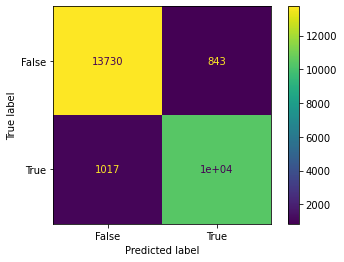

In [104]:
y_pred=ad_model.predict(X_test)
confusion_matrix3 = metrics.confusion_matrix(y_test, y_pred)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix3, display_labels = [False, True])

cm_display.plot()
plt.show()

In [105]:
#Adaboost Classifier Metrics
Accuracy2 = metrics.accuracy_score(y_test, y_pred)
Precision = metrics.precision_score(y_test, y_pred)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
F1_score = metrics.f1_score(y_test, y_pred)
#metrics
print({"Accuracy":Accuracy2,"Precision":Precision,"Sensitivity_recall":Sensitivity_recall,"Specificity":Specificity,"F1_score":F1_score})

{'Accuracy': 0.9283954419464121, 'Precision': 0.924926529521774, 'Sensitivity_recall': 0.9108129439621152, 'Specificity': 0.9421532971934399, 'F1_score': 0.9178154825026511}


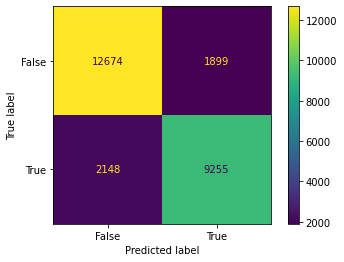

0.8442023406221127

In [107]:
#Naive Bayes Model and Confusion Matrix
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

confusion_matrix4 = metrics.confusion_matrix(y_test, y_pred)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix4, display_labels = [False, True])

cm_display.plot()
plt.show()

accuracy_score(y_pred,y_test)

In [108]:
#Naive Bayes Model Metrics
Accuracy3 = metrics.accuracy_score(y_test, y_pred)
Precision = metrics.precision_score(y_test, y_pred)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
F1_score = metrics.f1_score(y_test, y_pred)
#metrics
print({"Accuracy":Accuracy3,"Precision":Precision,"Sensitivity_recall":Sensitivity_recall,"Specificity":Specificity,"F1_score":F1_score})

{'Accuracy': 0.8442023406221127, 'Precision': 0.8297471759010221, 'Sensitivity_recall': 0.8116285188108393, 'Specificity': 0.8696905235709874, 'F1_score': 0.8205878441282085}
